In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


In [2]:
df = pd.read_csv("retail_store_inventory.csv")

In [3]:
df.head()


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [4]:
df['stockout_flag'] = np.where(
    df['Demand Forecast'] >
    df['Inventory Level'],
    1,
    0
)

In [5]:
df['stockout_flag'].value_counts()

stockout_flag
0    70515
1     2585
Name: count, dtype: int64

In [6]:
df['inventory_velocity'] = np.where(
    df['Inventory Level'] == 0,
    0,
    df['Units Sold'] /
    df['Inventory Level']
)

In [7]:
features = [

    'Inventory Level',
    'Units Sold',
    'Units Ordered',
    'Demand Forecast',
    'Price',
    'Discount',
    'Competitor Pricing',
    'inventory_velocity'

]

In [8]:
X = df[features]

y = df['stockout_flag']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42

)

In [10]:
model = RandomForestClassifier(

    n_estimators=100,

    random_state=42

)

In [11]:
model.fit(
    X_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [12]:
predictions = model.predict(X_test)

In [13]:
accuracy_score(
    y_test,
    predictions
)

0.9875512995896033

In [14]:
print(
    classification_report(
        y_test,
        predictions
    )
)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     14098
           1       0.90      0.74      0.81       522

    accuracy                           0.99     14620
   macro avg       0.94      0.87      0.90     14620
weighted avg       0.99      0.99      0.99     14620



In [15]:
importance = pd.DataFrame({

    'Feature': features,

    'Importance':
        model.feature_importances_

})

In [16]:
importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
7,inventory_velocity,0.376894
3,Demand Forecast,0.190244
0,Inventory Level,0.154717
1,Units Sold,0.099644
4,Price,0.052946
6,Competitor Pricing,0.052659
2,Units Ordered,0.052267
5,Discount,0.020630


In [17]:
top_driver = importance.sort_values(
    by='Importance',
    ascending=False
).iloc[0]['Feature']

print(
    f"Top stockout driver: {top_driver}"
)

Top stockout driver: inventory_velocity


In [18]:
df['availability_score'] = np.where(
    df['stockout_flag'] == 0,
    100,
    0
)

In [19]:
df['forecast_accuracy'] = np.where(

    df['Units Sold'] == 0,

    0,

    (
        1 -
        abs(
            df['Units Sold']
            -
            df['Demand Forecast']
        )
        /
        df['Units Sold']
    ) * 100

)

In [20]:
df['inventory_health_score'] = (

    df['availability_score'] * 0.4 +

    df['forecast_accuracy'] * 0.3 +

    np.minimum(
        df['inventory_velocity'] * 100,
        100
    ) * 0.2 +

    df['availability_score'] * 0.1

)

In [21]:
df['inventory_health_score'].mean()

np.float64(80.66367488526463)

In [22]:
inventory_value = (
    df['Inventory Level'] *
    df['Price']
).sum()

inventory_value

np.float64(1108476100.3000002)

In [23]:
inventory_turnover = (
    df['Units Sold'].sum()
    /
    df['Inventory Level'].mean()
)

inventory_turnover

np.float64(36344.90645516481)

In [24]:
predicted_stockouts = df[
    df['stockout_flag'] == 1
].shape[0]

predicted_stockouts

2585

In [25]:
overstock_count = df[
    df['Inventory Level']
    >
    (df['Demand Forecast'] * 1.5)
].shape[0]

overstock_count

47085

In [26]:
revenue_at_risk = (

    df.loc[
        df['stockout_flag'] == 1,
        'Demand Forecast'
    ]

    *

    df.loc[
        df['stockout_flag'] == 1,
        'Price'
    ]

).sum()

revenue_at_risk

np.float64(28755137.661399998)

In [27]:
print(f"Inventory Health Score: {df['inventory_health_score'].mean():.2f}")
print(f"Inventory Value: ${inventory_value:,.2f}")
print(f"Inventory Turnover: {inventory_turnover:.2f}")
print(f"Predicted Stockouts: {predicted_stockouts:,}")
print(f"Overstocked SKUs: {overstock_count:,}")
print(f"Revenue At Risk: ${revenue_at_risk:,.2f}")

Inventory Health Score: 80.66
Inventory Value: $1,108,476,100.30
Inventory Turnover: 36344.91
Predicted Stockouts: 2,585
Overstocked SKUs: 47,085
Revenue At Risk: $28,755,137.66


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

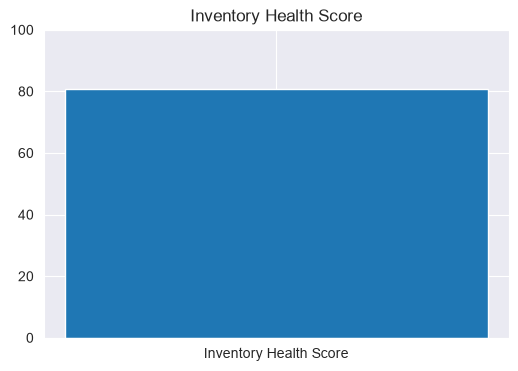

In [29]:
plt.figure(figsize=(6,4))

plt.bar(
    ['Inventory Health Score'],
    [df['inventory_health_score'].mean()]
)

plt.ylim(0,100)

plt.title('Inventory Health Score')

plt.show()

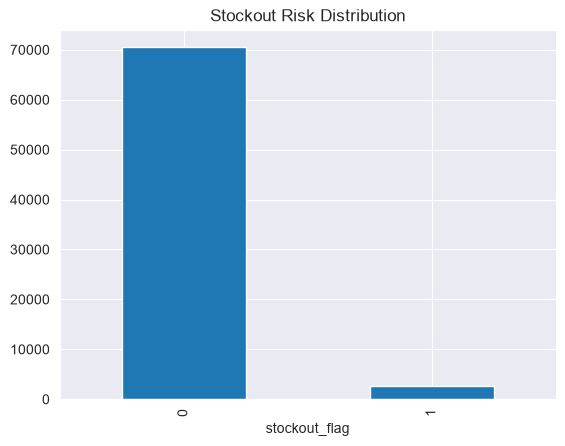

In [30]:
df['stockout_flag'].value_counts().plot(
    kind='bar'
)

plt.title('Stockout Risk Distribution')

plt.show()

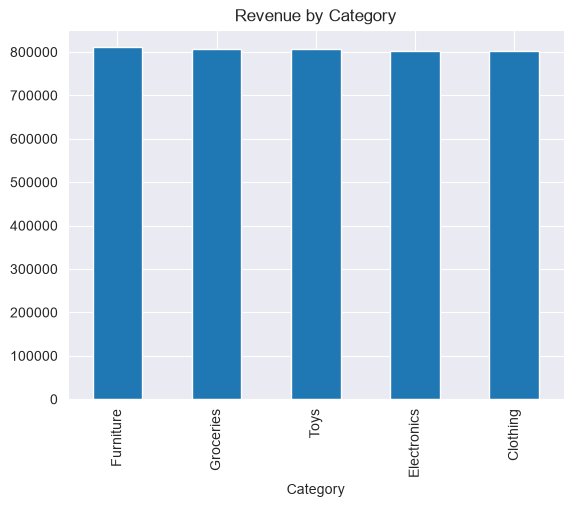

In [31]:
category_revenue = df.groupby(
    'Category'
)['Price'].sum()

category_revenue.sort_values(
    ascending=False
).plot(
    kind='bar'
)

plt.title('Revenue by Category')

plt.show()

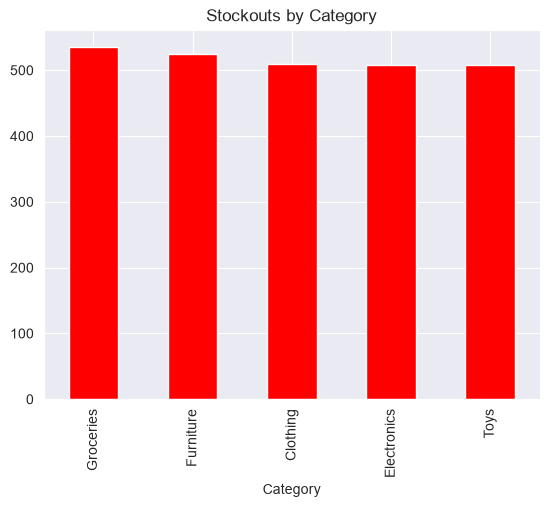

In [32]:
stockouts = df.groupby(
    'Category'
)['stockout_flag'].sum()

stockouts.sort_values(
    ascending=False
).plot(
    kind='bar',
    color='red'
)

plt.title('Stockouts by Category')

plt.show()

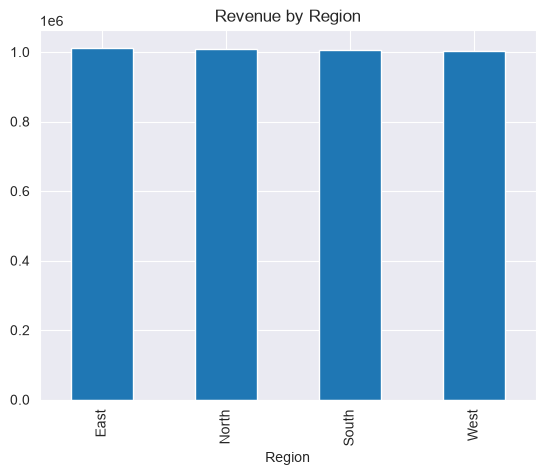

In [33]:
region_revenue = df.groupby(
    'Region'
)['Price'].sum()

region_revenue.plot(
    kind='bar'
)

plt.title('Revenue by Region')

plt.show()

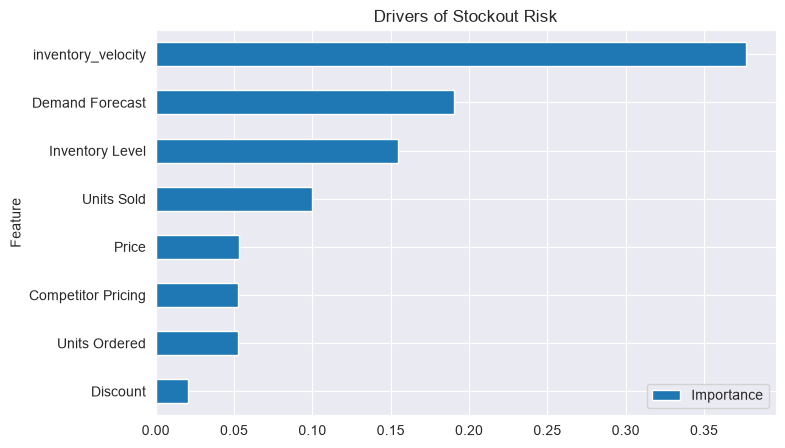

In [34]:
importance.sort_values(
    by='Importance'
).plot(

    x='Feature',
    y='Importance',
    kind='barh',

    figsize=(8,5)

)

plt.title(
    'Drivers of Stockout Risk'
)

plt.show()